In [188]:
# Import necessary libraries (same as the professor's FFNN example)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader, TensorDataset

import time

SEED = 42
# Set random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)


# TASK 1

In [189]:
# ------------------------------------------------------------------------------
# TASK 1
# ------------------------------------------------------------------------------

# ------------------------------------------------------------------------------
# LOAD DATASET
# ------------------------------------------------------------------------------
data = pd.read_csv("dataset_lab_1.csv")
data.columns = data.columns.str.strip()   # remove possible leading spaces in column names

print("Number of rows:", len(data))
data.head()

Number of rows: 31507


,Flow Duration,Flow IAT Mean,Fwd PSH Flags,Bwd Packet Length Mean,Bwd Packet Length Max,Flow Bytes/s,Down/Up Ratio,SYN Flag Count,Fwd Packet Length Mean,Fwd IAT Std,Packet Length Mean,Fwd Packet Length Max,Subflow Fwd Packets,Flow Packets/s,Total Fwd Packets,Destination Port,Label
0,303376,30337.600000,0,749.4,1448,12743.263,0,0,19.833334,98776.15,322.16666,119,6,36.258636,6,443,Benign
1,117,117.000000,0,0.0,0,0.000,1,0,0.000000,0.00,0.00000,0,1,17094.018000,1,52631,Benign
2,142,142.000000,0,0.0,0,84507.040,0,0,6.000000,0.00,6.00000,6,2,14084.507000,2,80,Benign
3,191,63.666668,0,52.0,52,921465.940,1,0,36.000000,0.00,42.40000,36,2,20942.408000,2,53,Benign
4,4,4.000000,0,0.0,0,3000000.000,0,0,6.000000,0.00,6.00000,6,2,500000.000000,2,49467,Benign


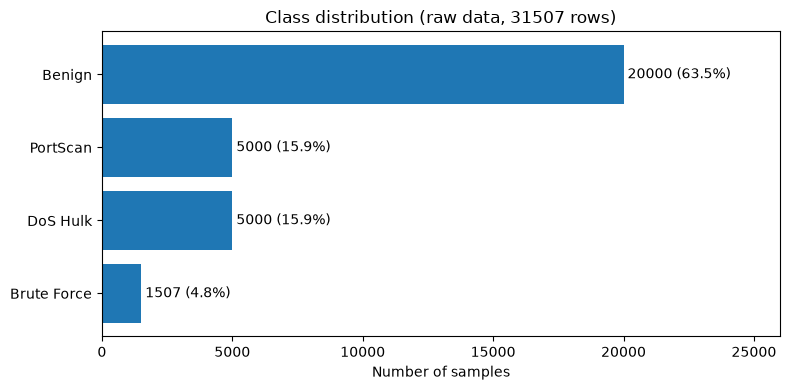

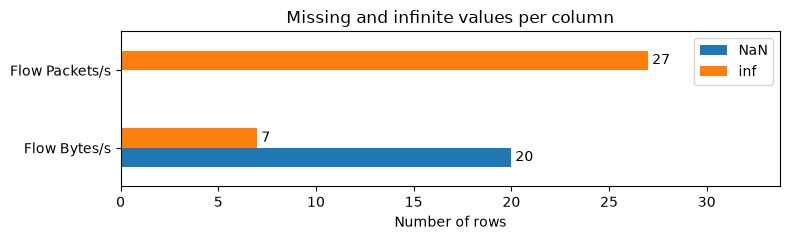

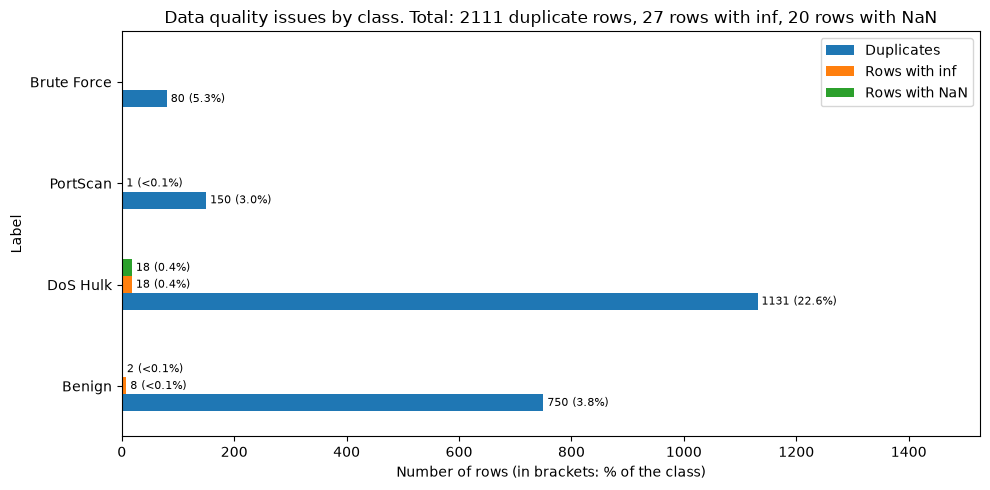

/tmp/ipykernel_7204/203762849.py:76: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([num_box[c].dropna() for c in order], vert=False,


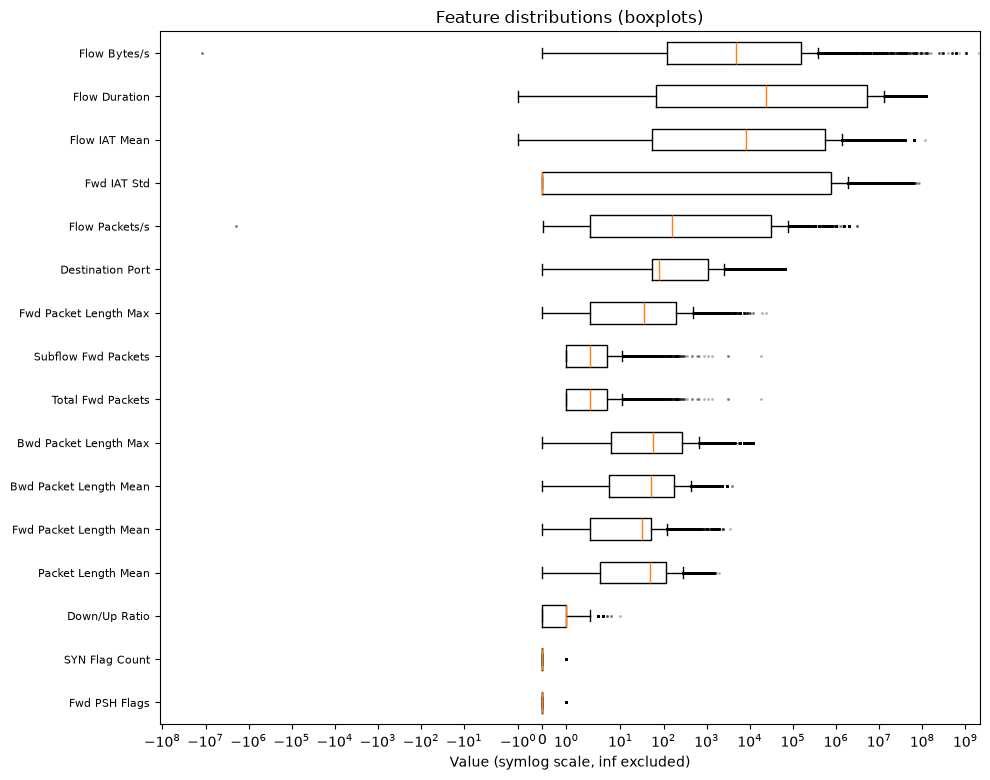

In [190]:
# ------------------------------------------------------------------------------
# INSPECTION
# ------------------------------------------------------------------------------

# Classes and balance
counts_raw = data["Label"].value_counts()   # saved for the raw vs cleaned comparison
counts = counts_raw.sort_values()
perc = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index, counts.values)
for i, (c, p) in enumerate(zip(counts.values, perc.values)):
    ax.text(c, i, f" {c} ({p:.1f}%)", va="center")
ax.set_xlim(0, counts.max() * 1.3)   # room for the labels on the longest bar
ax.set_xlabel("Number of samples")
ax.set_title(f"Class distribution (raw data, {len(data)} rows)")
plt.tight_layout()
plt.show()
plt.close()

# Missing and infinite values per column
num = data.drop(columns=["Label"])
bad_cols = pd.DataFrame({"NaN": num.isna().sum(), "inf": np.isinf(num).sum()})
bad_cols = bad_cols[(bad_cols > 0).any(axis=1)]

if len(bad_cols) > 0:
    ax = bad_cols.plot.barh(figsize=(8, 0.5 * len(bad_cols) + 1.5))
    for cont in ax.containers:   # exact numbers on the bars (0 hidden)
        ax.bar_label(cont, labels=[f" {int(v)}" if v > 0 else "" for v in cont.datavalues])
    ax.set_xlim(0, bad_cols.values.max() * 1.25)
    ax.set_xlabel("Number of rows")
    ax.set_title("Missing and infinite values per column")
    plt.tight_layout()
    plt.show()
    plt.close()
else:
    print("No NaN or inf values found")

# Data quality issues by class: number of rows and % of each class in one plot
dup_mask = data.duplicated()
inf_mask = np.isinf(num).any(axis=1)
nan_mask = data.isna().any(axis=1)

issues = pd.DataFrame({
    "Duplicates": data[dup_mask]["Label"].value_counts(),
    "Rows with inf": data[inf_mask]["Label"].value_counts(),
    "Rows with NaN": data[nan_mask]["Label"].value_counts(),
}).reindex(counts_raw.index).fillna(0).astype(int)
issues_perc = issues.div(counts_raw, axis=0) * 100

ax = issues.plot.barh(figsize=(10, 5))
for cont, col in zip(ax.containers, issues.columns):
    labels = []
    for n, p in zip(issues[col], issues_perc[col]):
        if n == 0:
            labels.append("")
        elif p < 0.1:
            labels.append(f" {n} (<0.1%)")
        else:
            labels.append(f" {n} ({p:.1f}%)")
    ax.bar_label(cont, labels=labels, fontsize=8)
ax.set_xlim(0, issues.values.max() * 1.35)   # room for the labels
ax.set_xlabel("Number of rows (in brackets: % of the class)")
ax.set_title(f"Data quality issues by class. Total: {dup_mask.sum()} duplicate rows, "
             f"{inf_mask.sum()} rows with inf, {nan_mask.sum()} rows with NaN")
plt.tight_layout()
plt.show()
plt.close()


# Feature distributions: boxplots on a shared symlog axis (inf excluded)
num_box = num.replace([np.inf, -np.inf], np.nan)
order = num_box.max().sort_values().index   # most extreme features at the top

fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 1.5))
ax.boxplot([num_box[c].dropna() for c in order], vert=False,
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order, fontsize=8)
ax.set_xscale("symlog")   # log scale that also handles 0 and negative values
ax.set_xlabel("Value (symlog scale, inf excluded)")
ax.set_title("Feature distributions (boxplots)")
plt.tight_layout()
plt.show()
plt.close()


Number of rows before duplicates 31507
Number of rows after duplicates 29396
Number of rows after missing values 29386

Class counts after cleaning:
 Label
Benign         19242
PortScan        4849
DoS Hulk        3868
Brute Force     1427
Name: count, dtype: int64


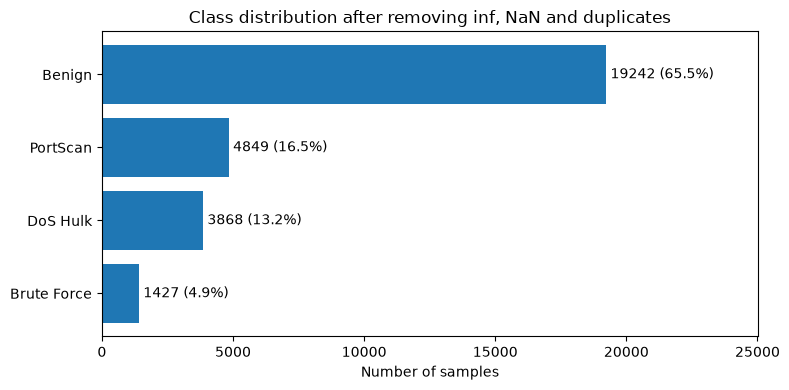


Encoding: {'Benign': 0, 'Brute Force': 1, 'DoS Hulk': 2, 'PortScan': 3}


In [191]:
# ------------------------------------------------------------------------------
# PREPROCESSING
# ------------------------------------------------------------------------------

# Treat inf as missing values
data = data.replace([np.inf, -np.inf], np.nan)

# Remove duplicates
print("\nNumber of rows before duplicates", len(data))
data = data.drop_duplicates()
print("Number of rows after duplicates", len(data))

# Remove rows with missing values
data = data.dropna()
print("Number of rows after missing values", len(data))

counts_clean = data["Label"].value_counts()
print("\nClass counts after cleaning:\n", counts_clean)

# Class balance plot after cleaning (before LabelEncoder, so class names are visible)
counts = counts_clean.sort_values()
perc = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index, counts.values)
for i, (c, p) in enumerate(zip(counts.values, perc.values)):
    ax.text(c, i, f" {c} ({p:.1f}%)", va="center")
ax.set_xlim(0, counts.max() * 1.3)   # room for the labels on the longest bar
ax.set_xlabel("Number of samples")
ax.set_title("Class distribution after removing inf, NaN and duplicates")
plt.tight_layout()
plt.show()
plt.close()

# Encode labels
label_encoder = LabelEncoder()
data["Label"] = label_encoder.fit_transform(data["Label"])
print("\nEncoding:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

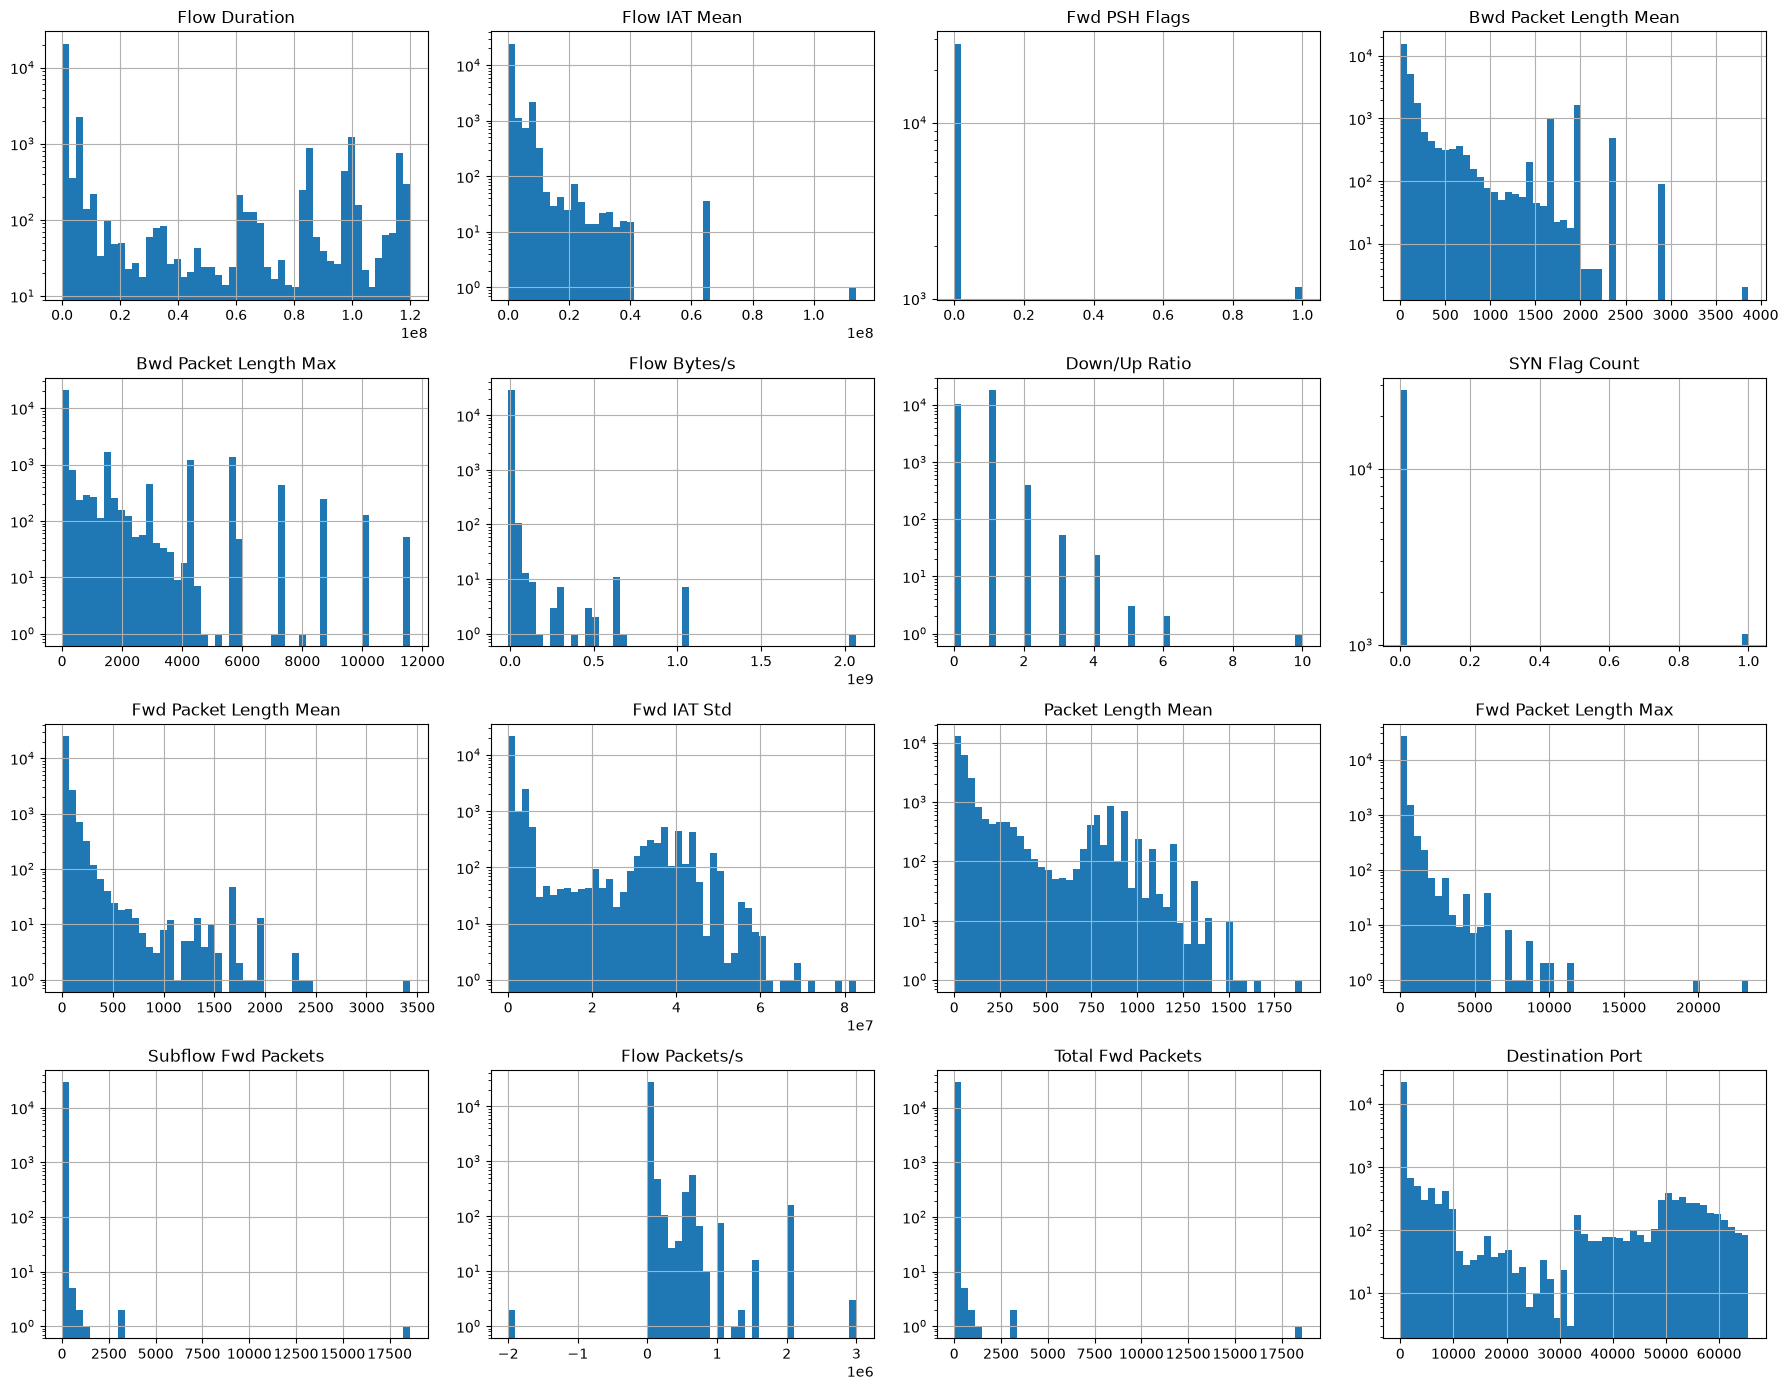

In [192]:
# ------------------------------------------------------------------------------
# DATA VISUALIZATION
# ------------------------------------------------------------------------------

# Too many features for a scatter plot: histograms of each feature instead
data.drop(columns=["Label"]).hist(bins=50, figsize=(18, 14), log=True)
plt.tight_layout()
plt.show()
plt.close()

In [193]:
# ------------------------------------------------------------------------------
# SPLITTING
# ------------------------------------------------------------------------------

feature_names = data.drop(columns=["Label"]).columns.tolist()
X = data[feature_names].values
y = data["Label"].values

# stratify=y keeps the same class proportions in every partition (imbalanced classes)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

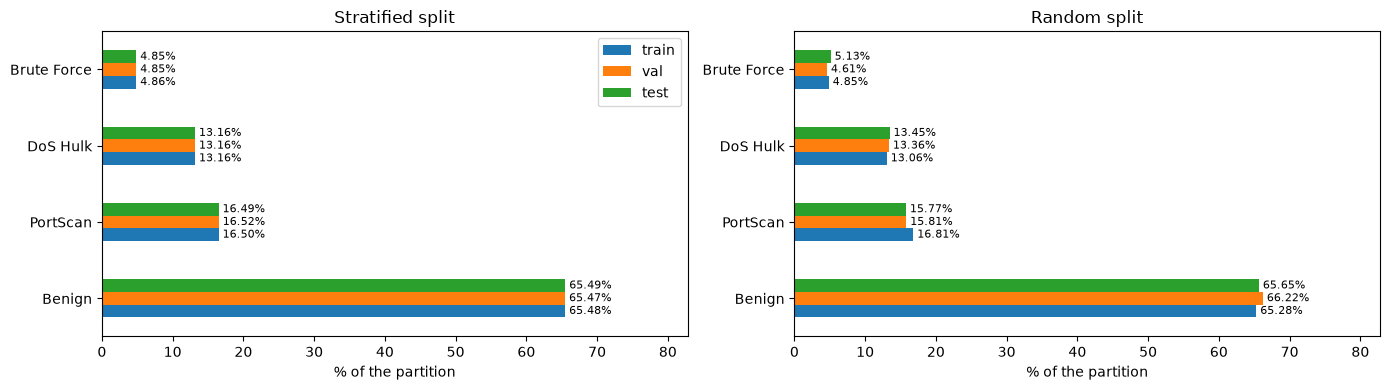

In [194]:
# ------------------------------------------------------------------------------
# STRATIFICATION CHECK: same split (seed 42) with and without stratify
# ------------------------------------------------------------------------------
def split_proportions(stratified):
    y_tr, y_tmp = train_test_split(y, test_size=0.3, random_state=42,
                                   stratify=y if stratified else None)
    y_v, y_t = train_test_split(y_tmp, test_size=0.5, random_state=42,
                                stratify=y_tmp if stratified else None)
    return pd.DataFrame({
        name: pd.Series(label_encoder.inverse_transform(yy)).value_counts(normalize=True) * 100
        for name, yy in [("train", y_tr), ("val", y_v), ("test", y_t)]
    })

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, stratified, title in [(axes[0], True, "Stratified split"), (axes[1], False, "Random split")]:
    perc = split_proportions(stratified)
    perc.plot.barh(ax=ax, legend=(ax is axes[0]))
    for cont in ax.containers:
        ax.bar_label(cont, fmt=" %.2f%%", fontsize=8)
    ax.set_xlabel("% of the partition")
    ax.set_title(title)
axes[0].set_xlim(0, perc.values.max() * 1.25)   # room for the labels (shared by both panels)
plt.tight_layout()
plt.show()
plt.close()

/tmp/ipykernel_7204/2096987421.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([X_train_df[c] for c in order], vert=False,


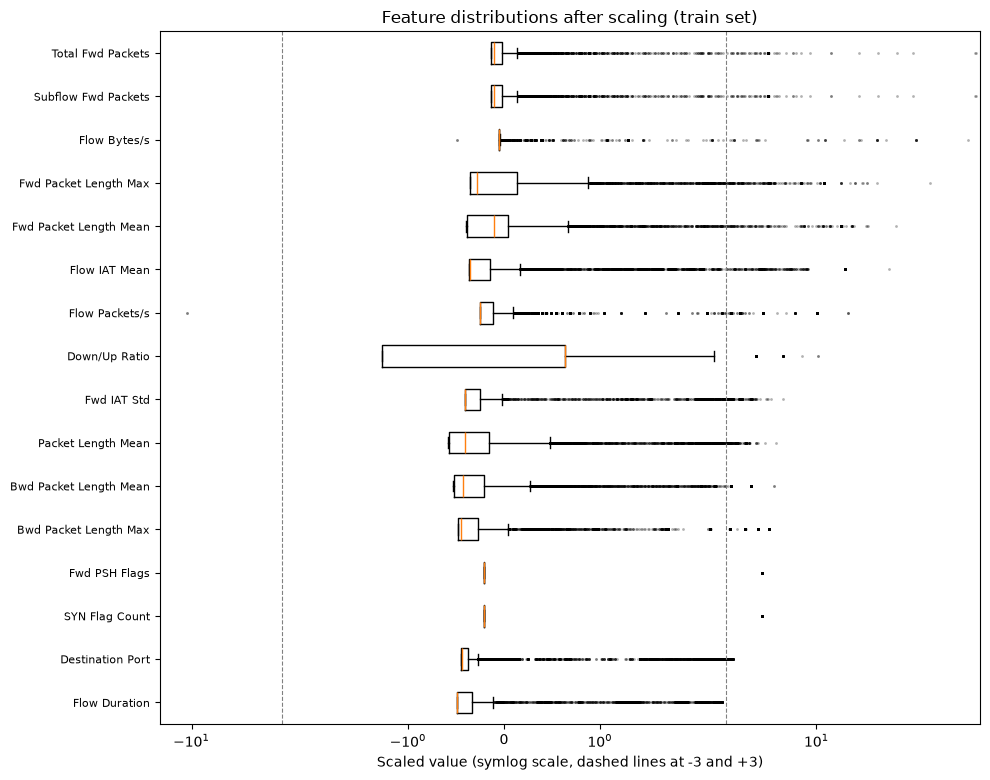

In [195]:
# ------------------------------------------------------------------------------
# STANDARDIZATION
# ------------------------------------------------------------------------------
# Fit ONLY on the training set, then apply to validation and test
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Feature distributions after scaling (train set)
X_train_df = pd.DataFrame(X_train, columns=feature_names)
order = X_train_df.max().sort_values().index   # most extreme features at the top

fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 1.5))
ax.boxplot([X_train_df[c] for c in order], vert=False,
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order, fontsize=8)
ax.axvline(-3, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(3, color="gray", linestyle="--", linewidth=0.8)
ax.set_xscale("symlog")   # log scale that also handles 0 and negative values
ax.set_xlabel("Scaled value (symlog scale, dashed lines at -3 and +3)")
ax.set_title("Feature distributions after scaling (train set)")
plt.tight_layout()
plt.show()
plt.close()

# TASK 2

In [196]:
# ------------------------------------------------------------------------------
# TASK 2
# ------------------------------------------------------------------------------

# ===== CELLA 2: tensori, dataset, dataloader =====
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor   = torch.tensor(X_val,   dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val,   dtype=torch.long)
X_test_tensor  = torch.tensor(X_test,  dtype=torch.float32)   # creato ma NON usato in 2A
y_test_tensor  = torch.tensor(y_test,  dtype=torch.long)

BATCH_SIZE = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,   y_val_tensor)

g = torch.Generator().manual_seed(SEED)                      # shuffle riproducibile
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)

class_names = list(label_encoder.classes_)
n_features, n_classes = X_train.shape[1], len(class_names)
print(n_features, "feature,", n_classes, "classi")
print("Train:", np.bincount(y_train), "| Val:", np.bincount(y_val))

16 feature, 4 classi
Train: [13469   999  2708  3394] | Val: [2886  214  580  728]


In [197]:
# ===== CELLA 3: modello (1 hidden layer) =====
class SimpleFFNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleFFNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)          # logit grezzi: la softmax e' dentro CrossEntropyLoss
        return x

In [198]:
# ===== CELLA 4: training loop (struttura del professore) =====
def training_loop(model, train_loader, val_loader, train_dataset, val_dataset,
                  device, optimizer, criterion, num_epochs=100,
                  min_delta=None, patience=None):
    """
    Allena il modello, traccia train/val loss e macro-F1 di validation per epoca,
    applica early stopping sulla val loss e ripristina i pesi della best epoch.
    Ritorna un dizionario con le curve, la best epoch e il tempo.
    """
    start_time = time.time()
    train_losses, val_losses, val_f1s = [], [], []
    best_val_loss = float('inf')
    best_epoch = 0
    trigger_times = 0
    best_model_state = None

    for epoch in range(num_epochs):
        # ---- Train ----
        train_loss = 0
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch_X.size(0)
        train_loss /= len(train_dataset)
        train_losses.append(train_loss)

        # ---- Validation ----
        val_loss = 0
        preds, labs = [], []
        model.eval()
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                val_outputs = model(batch_X)
                loss = criterion(val_outputs, batch_y)
                val_loss += loss.item() * batch_X.size(0)
                preds.append(val_outputs.argmax(1).cpu().numpy())
                labs.append(batch_y.cpu().numpy())
        val_loss /= len(val_dataset)
        val_losses.append(val_loss)
        val_f1s.append(f1_score(np.concatenate(labs), np.concatenate(preds),
                                average="macro", zero_division=0))

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, '
                  f'Val Loss: {val_loss:.4f}, Val macro-F1: {val_f1s[-1]:.4f}')

        # ---- Early stopping (sulla val loss) ----
        if min_delta is not None:
            if val_loss < best_val_loss - min_delta:
                best_val_loss = val_loss
                best_epoch = epoch
                best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                trigger_times = 0
            else:
                trigger_times += 1
                if trigger_times >= patience:
                    print(f"Early stopping at epoch {epoch+1} "
                          f"(best epoch {best_epoch+1}, best val loss: {best_val_loss:.6f})")
                    break

    # ---- Restore best model ----
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    elapsed_time = time.time() - start_time
    print(f'The function took {elapsed_time:.4f} seconds to execute.')

    # ---- Plot ----
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(train_losses, label='Train Loss')
    ax[0].plot(val_losses, label='Validation Loss')
    ax[0].axvline(best_epoch, ls='--', color='gray', label='Best epoch')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
    ax[0].set_title('Training and Validation Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(val_f1s, color='green')
    ax[1].axvline(best_epoch, ls='--', color='gray')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Macro-F1 (val)')
    ax[1].set_title('Validation macro-F1'); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

    return {"train_losses": train_losses, "val_losses": val_losses, "val_f1s": val_f1s,
            "best_epoch": best_epoch, "n_epochs": len(train_losses), "time_s": elapsed_time}


def predict(model, dataloader, device):
    """Ritorna (etichette vere, predizioni) su un dataloader."""
    model.eval()
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_labels.extend(labels.numpy())
            all_predictions.extend(predicted.cpu().numpy())
    return np.array(all_labels), np.array(all_predictions)

Using device: cuda
Epoch 1/100, Train Loss: 0.7464, Val Loss: 0.4959, Val macro-F1: 0.5561
Epoch 10/100, Train Loss: 0.1925, Val Loss: 0.2039, Val macro-F1: 0.8957
Epoch 20/100, Train Loss: 0.1596, Val Loss: 0.1742, Val macro-F1: 0.8993
Epoch 30/100, Train Loss: 0.1474, Val Loss: 0.1611, Val macro-F1: 0.9030
Epoch 40/100, Train Loss: 0.1393, Val Loss: 0.1503, Val macro-F1: 0.9146
Epoch 50/100, Train Loss: 0.1330, Val Loss: 0.1432, Val macro-F1: 0.9175
Epoch 60/100, Train Loss: 0.1283, Val Loss: 0.1343, Val macro-F1: 0.9183
Epoch 70/100, Train Loss: 0.1244, Val Loss: 0.1299, Val macro-F1: 0.9219
Epoch 80/100, Train Loss: 0.1211, Val Loss: 0.1272, Val macro-F1: 0.9242
Epoch 90/100, Train Loss: 0.1185, Val Loss: 0.1231, Val macro-F1: 0.9225
Epoch 100/100, Train Loss: 0.1162, Val Loss: 0.1226, Val macro-F1: 0.9176
The function took 120.7896 seconds to execute.


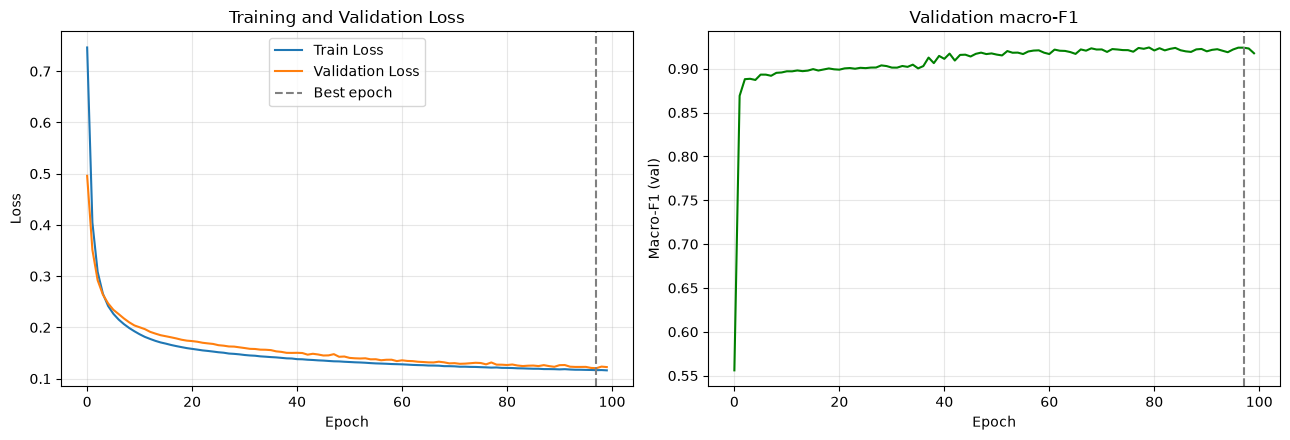

In [199]:
# ===== CELLA 5: RUN 2A =====
import pickle
from sklearn.metrics import f1_score

# Define the execution device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Scelte dichiarate: 1 hidden layer x 64, ReLU, CrossEntropy (senza pesi), AdamW lr=5e-4,
# batch 64, max 100 epoche, early stopping su val loss (patience=10, min_delta=1e-5), seed 42
torch.manual_seed(SEED)                                  # stessa init dei pesi a ogni run
model = SimpleFFNN(n_features, 64, n_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4)

min_delta = 1e-5
patience = 10

hist_2A = training_loop(model, train_loader, val_loader, train_dataset, val_dataset,
                        device, optimizer, criterion, num_epochs=100,
                        min_delta=min_delta, patience=patience)

torch.save(model.state_dict(), "baseline_2A.pt")         # servono in 2C e Task 3
pickle.dump(hist_2A, open("hist_2A.pkl", "wb"))

In [200]:
# ===== CELLA 6: report di VALIDATION (richiesto dal lab) =====
from sklearn.metrics import classification_report, confusion_matrix

v_true, v_pred = predict(model, val_loader, device)
print(classification_report(v_true, v_pred, target_names=class_names, digits=3))
print("Matrice di confusione (righe = vere, colonne = predette):")
print(confusion_matrix(v_true, v_pred))
print(f"\nBest epoch: {hist_2A['best_epoch']+1} | epoche eseguite: {hist_2A['n_epochs']} "
      f"| tempo: {hist_2A['time_s']:.1f} s")

              precision    recall  f1-score   support

      Benign      0.963     0.968     0.965      2886
 Brute Force      0.759     0.944     0.842       214
    DoS Hulk      0.998     0.917     0.956       580
    PortScan      0.946     0.920     0.933       728

    accuracy                          0.952      4408
   macro avg      0.917     0.937     0.924      4408
weighted avg      0.955     0.952     0.953      4408

Matrice di confusione (righe = vere, colonne = predette):
[[2793   64    1   28]
 [   2  202    0   10]
 [  48    0  532    0]
 [  58    0    0  670]]

Best epoch: 98 | epoche eseguite: 100 | tempo: 120.8 s
